In [43]:
import numpy as np

In [44]:
import pandas as pd

In [45]:
import matplotlib.pyplot as plt

In [46]:
import seaborn as sns

In [47]:
sns.set(style='whitegrid')

In [48]:
df=pd.read_csv('threat_detection.csv')

In [49]:
df.head(10)

,Alert ID,Hour,Protocol,Dest Port,Packets,Bytes,Duration,Source Type,Threat Type,Severity,Status,Threat Score,Is Attack
0,1,6,TCP,53,722,304684,799,Remote,Normal,Low,Missed,23.0,0
1,2,19,HTTPS,443,4078,4159560,158,Internal,Normal,Medium,Missed,19.3,0
2,3,14,HTTPS,443,386,514924,702,Internal,Normal,Low,Investigating,30.9,0
3,4,10,UDP,22,2818,450880,100,External,SQL Injection,Medium,Blocked,43.8,1
4,5,7,TCP,3389,2888,1288048,2601,Internal,Malware,High,Detected,41.2,1
5,6,20,TCP,3389,2720,772480,4575,Cloud,Normal,Medium,Missed,13.9,0
6,7,6,TCP,445,260,27300,2017,Internal,Phishing,Low,Detected,41.9,1
7,8,18,HTTP,445,4489,4403709,2148,External,Normal,Low,Missed,18.2,0
8,9,22,UDP,445,600,160200,1287,Internal,Normal,Low,Blocked,17.0,0
9,10,10,TCP,22,3256,2998776,349,External,Normal,Low,Missed,22.3,0


In [50]:
df.tail(10)

,Alert ID,Hour,Protocol,Dest Port,Packets,Bytes,Duration,Source Type,Threat Type,Severity,Status,Threat Score,Is Attack
3990,3991,11,HTTPS,8080,2225,1272700,1528,External,Normal,Low,Missed,9.3,0
3991,3992,20,HTTP,3389,4523,2854013,581,Internal,Brute Force,Low,Investigating,68.7,1
3992,3993,7,TCP,8080,2788,2447864,1803,Cloud,Normal,Low,Missed,22.0,0
3993,3994,21,HTTPS,445,4627,6408395,1642,Remote,Phishing,Medium,Detected,31.6,1
3994,3995,21,HTTPS,25,4344,2554272,514,External,Insider Threat,Medium,Missed,13.5,1
3995,3996,0,TCP,3389,4312,4644024,1858,External,Normal,Medium,Missed,13.3,0
3996,3997,3,TCP,3306,4809,1250340,3201,Internal,Malware,Low,Blocked,24.2,1
3997,3998,20,ICMP,25,438,400770,3290,Internal,Normal,Low,Detected,25.6,0
3998,3999,10,TCP,3306,2359,3429986,133,Internal,Ransomware,Critical,Investigating,69.3,1
3999,4000,2,UDP,53,3855,2764035,449,Internal,Ransomware,High,Detected,79.6,1


In [51]:
print(df.shape)

(4000, 13)


In [52]:
print(df.columns)

Index(['Alert ID', 'Hour', 'Protocol', 'Dest Port', 'Packets', 'Bytes',
       'Duration', 'Source Type', 'Threat Type', 'Severity', 'Status',
       'Threat Score', 'Is Attack'],
      dtype='str')


In [53]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Alert ID      4000 non-null   int64  
 1   Hour          4000 non-null   int64  
 2   Protocol      4000 non-null   str    
 3   Dest Port     4000 non-null   int64  
 4   Packets       4000 non-null   int64  
 5   Bytes         4000 non-null   int64  
 6   Duration      4000 non-null   int64  
 7   Source Type   4000 non-null   str    
 8   Threat Type   4000 non-null   str    
 9   Severity      4000 non-null   str    
 10  Status        4000 non-null   str    
 11  Threat Score  4000 non-null   float64
 12  Is Attack     4000 non-null   int64  
dtypes: float64(1), int64(7), str(5)
memory usage: 528.5 KB
None


In [54]:
print(df.describe())

          Alert ID         Hour    Dest Port      Packets         Bytes  \
count  4000.000000  4000.000000  4000.000000  4000.000000  4.000000e+03   
mean   2000.500000    11.468500  1535.528000  2498.713750  1.904351e+06   
std    1154.844867     7.014685  2451.462157  1429.669568  1.618855e+06   
min       1.000000     0.000000    21.000000     1.000000  4.550000e+02   
25%    1000.750000     5.000000    25.000000  1286.250000  5.793652e+05   
50%    2000.500000    12.000000    80.000000  2513.000000  1.458434e+06   
75%    3000.250000    18.000000  3306.000000  3724.250000  2.874962e+06   
max    4000.000000    23.000000  8080.000000  4999.000000  7.403116e+06   

           Duration  Threat Score    Is Attack  
count   4000.000000   4000.000000  4000.000000  
mean    2039.480750     33.354900     0.649750  
std     1992.879604     21.779354     0.477108  
min       10.000000      0.000000     0.000000  
25%      606.750000     16.375000     0.000000  
50%     1447.500000     28.300

In [55]:
print(df.describe(include='all'))

           Alert ID         Hour Protocol    Dest Port      Packets  \
count   4000.000000  4000.000000     4000  4000.000000  4000.000000   
unique          NaN          NaN        5          NaN          NaN   
top             NaN          NaN      TCP          NaN          NaN   
freq            NaN          NaN     1639          NaN          NaN   
mean    2000.500000    11.468500      NaN  1535.528000  2498.713750   
std     1154.844867     7.014685      NaN  2451.462157  1429.669568   
min        1.000000     0.000000      NaN    21.000000     1.000000   
25%     1000.750000     5.000000      NaN    25.000000  1286.250000   
50%     2000.500000    12.000000      NaN    80.000000  2513.000000   
75%     3000.250000    18.000000      NaN  3306.000000  3724.250000   
max     4000.000000    23.000000      NaN  8080.000000  4999.000000   

               Bytes      Duration Source Type Threat Type Severity  Status  \
count   4.000000e+03   4000.000000        4000        4000     4000 

In [56]:
print("Missing values:\n", df.isnull().sum())

Missing values:
 Alert ID        0
Hour            0
Protocol        0
Dest Port       0
Packets         0
Bytes           0
Duration        0
Source Type     0
Threat Type     0
Severity        0
Status          0
Threat Score    0
Is Attack       0
dtype: int64


In [57]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [58]:
print(df.dtypes)

Alert ID          int64
Hour              int64
Protocol            str
Dest Port         int64
Packets           int64
Bytes             int64
Duration          int64
Source Type         str
Threat Type         str
Severity            str
Status              str
Threat Score    float64
Is Attack         int64
dtype: object


In [59]:
print(df.nunique())

Alert ID        4000
Hour              24
Protocol           5
Dest Port         10
Packets         2753
Bytes           3993
Duration        2663
Source Type        4
Threat Type        8
Severity           4
Status             4
Threat Score     834
Is Attack          2
dtype: int64


In [60]:
print(df['Threat Type'].value_counts())

Threat Type
Normal            1401
Phishing           712
Malware            495
Brute Force        405
DDoS               305
SQL Injection      294
Ransomware         219
Insider Threat     169
Name: count, dtype: int64


In [61]:
print(df['Severity'].value_counts())

Severity
Low         1397
Medium      1285
High         882
Critical     436
Name: count, dtype: int64


In [62]:
print(df['Status'].value_counts())

Status
Missed           1330
Detected         1305
Blocked           974
Investigating     391
Name: count, dtype: int64


C:\Users\harsh\AppData\Local\Temp\ipykernel_37988\2780516289.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Threat Type', data=df, palette='Set2')


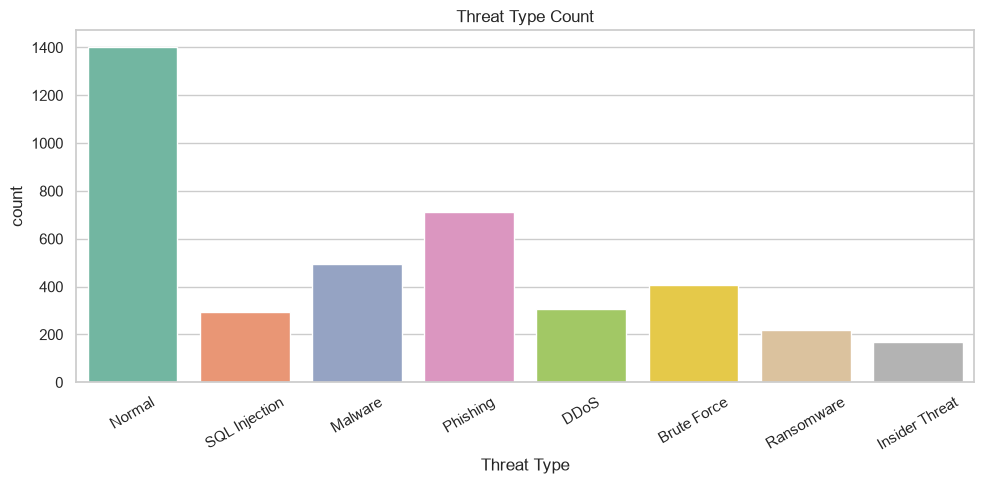

In [63]:
plt.figure(figsize=(10,5))
sns.countplot(x='Threat Type', data=df, palette='Set2')
plt.xticks(rotation=30)
plt.title('Threat Type Count')
plt.tight_layout()
plt.show()

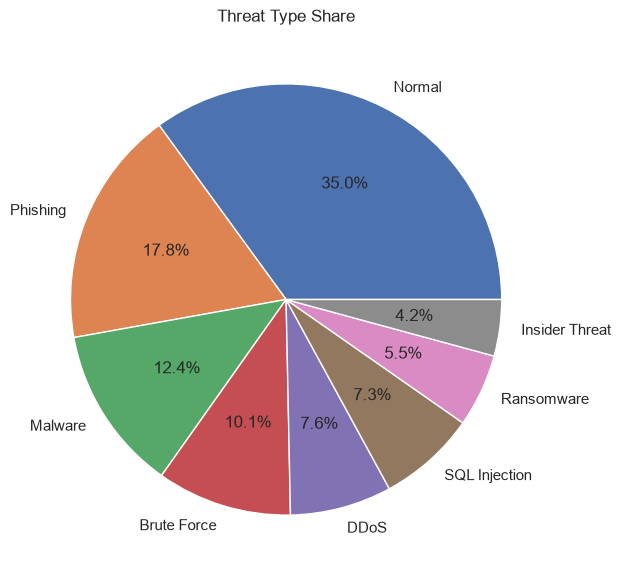

In [64]:
a=df['Threat Type'].value_counts()
plt.figure(figsize=(7,7))
plt.pie(a, labels=a.index, autopct='%1.1f%%')
plt.title('Threat Type Share')
plt.show()

C:\Users\harsh\AppData\Local\Temp\ipykernel_37988\2797505859.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Severity', data=df, palette='Reds', order=['Low','Medium','High','Critical'])


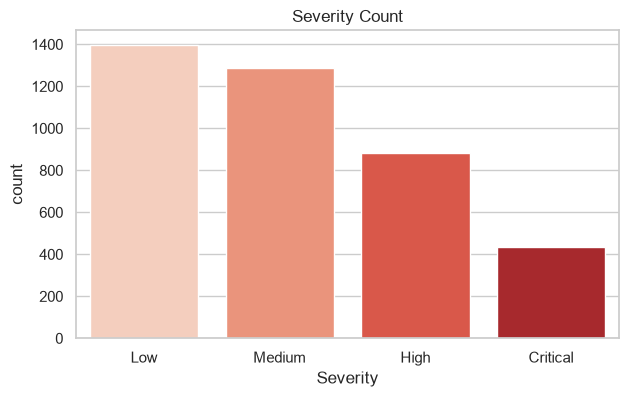

In [65]:
plt.figure(figsize=(7,4))
sns.countplot(x='Severity', data=df, palette='Reds', order=['Low','Medium','High','Critical'])
plt.title('Severity Count')
plt.show()

C:\Users\harsh\AppData\Local\Temp\ipykernel_37988\3563906199.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Status', data=df, palette='Set1')


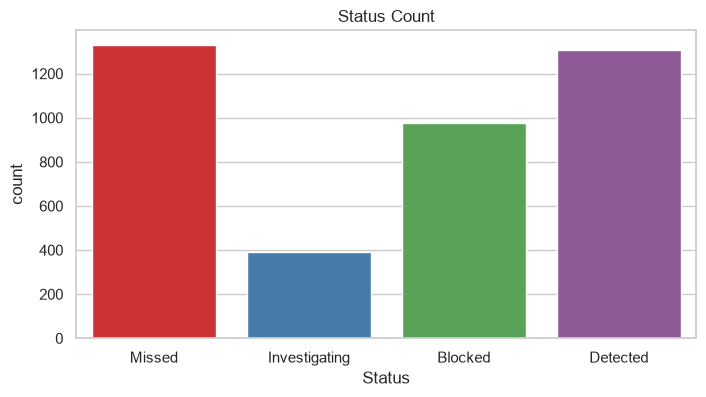

In [66]:
plt.figure(figsize=(8,4))
sns.countplot(x='Status', data=df, palette='Set1')
plt.title('Status Count')
plt.show()

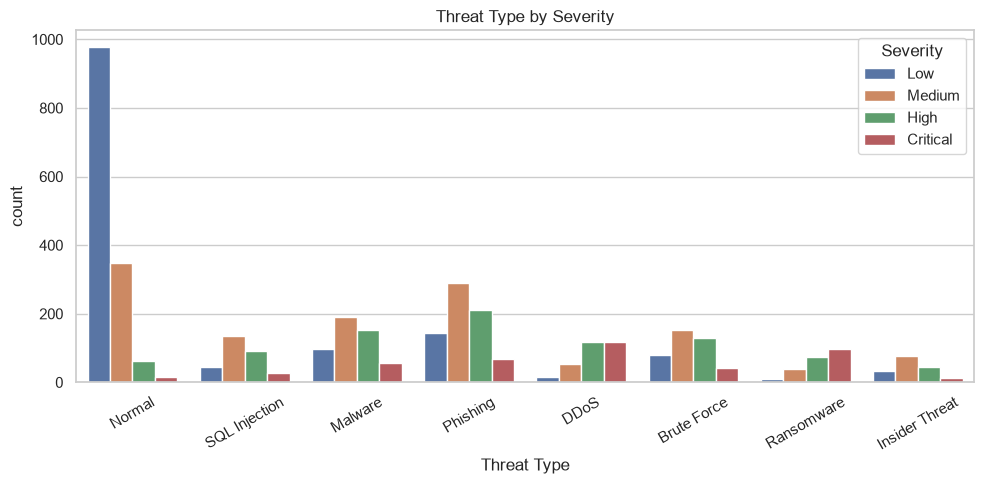

In [67]:
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='Threat Type', hue='Severity')
plt.xticks(rotation=30)
plt.title('Threat Type by Severity')
plt.tight_layout()
plt.show()

C:\Users\harsh\AppData\Local\Temp\ipykernel_37988\3221207737.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Threat Type', y='Threat Score', data=df, palette='coolwarm')


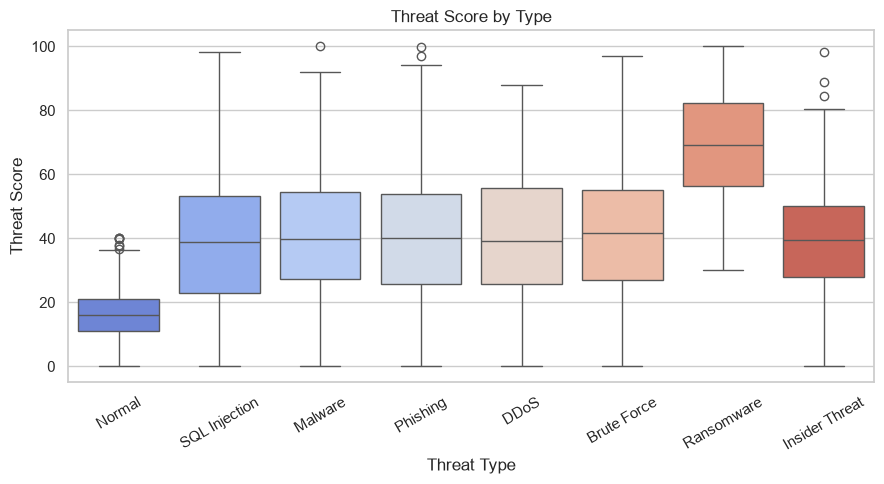

In [68]:
plt.figure(figsize=(9,5))
sns.boxplot(x='Threat Type', y='Threat Score', data=df, palette='coolwarm')
plt.xticks(rotation=30)
plt.title('Threat Score by Type')
plt.tight_layout()
plt.show()

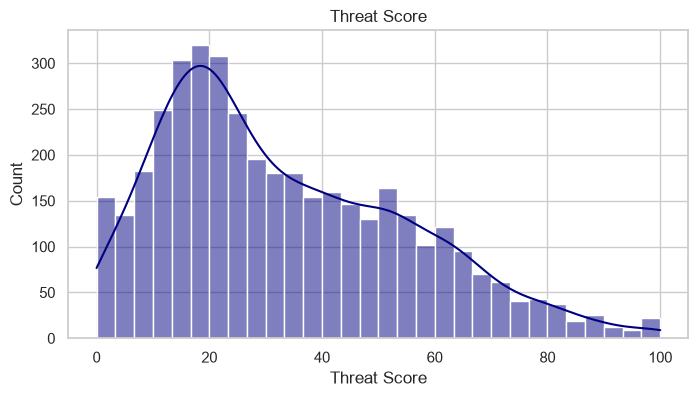

In [69]:
plt.figure(figsize=(8,4))
sns.histplot(df['Threat Score'], bins=30, kde=True, color='navy')
plt.title('Threat Score')
plt.show()

C:\Users\harsh\AppData\Local\Temp\ipykernel_37988\1574357227.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Severity', y='Packets', data=df, palette='Set3', order=['Low','Medium','High','Critical'])


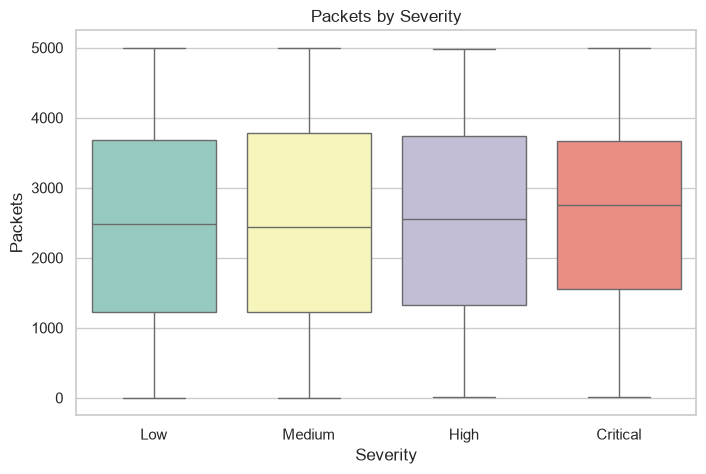

In [70]:
plt.figure(figsize=(8,5))
sns.boxplot(x='Severity', y='Packets', data=df, palette='Set3', order=['Low','Medium','High','Critical'])
plt.title('Packets by Severity')
plt.show()

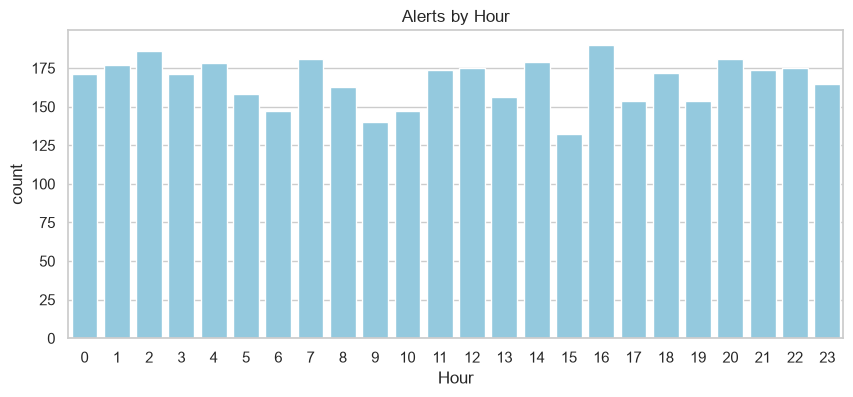

In [71]:
plt.figure(figsize=(10,4))
sns.countplot(data=df, x='Hour', color='skyblue')
plt.title('Alerts by Hour')
plt.show()

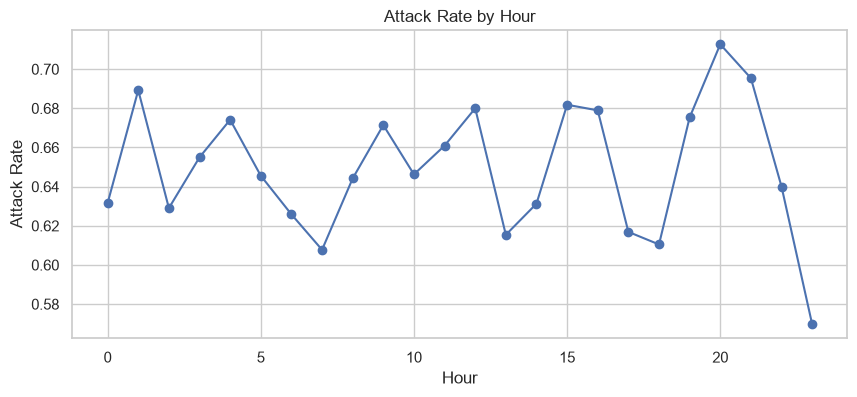

In [72]:
h=df.groupby('Hour')['Is Attack'].mean()
plt.figure(figsize=(10,4))
plt.plot(h.index, h.values, marker='o')
plt.title('Attack Rate by Hour')
plt.xlabel('Hour')
plt.ylabel('Attack Rate')
plt.show()

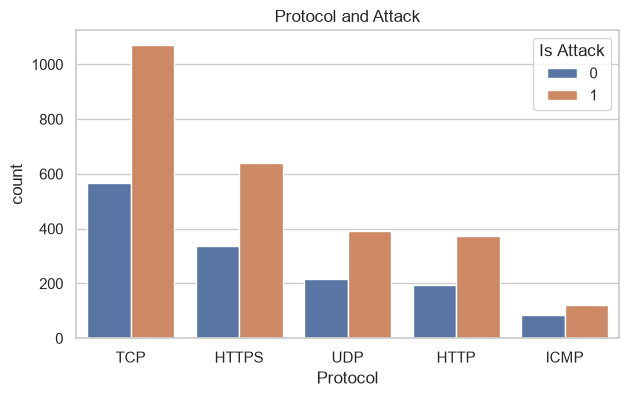

In [73]:
plt.figure(figsize=(7,4))
sns.countplot(data=df, x='Protocol', hue='Is Attack')
plt.title('Protocol and Attack')
plt.show()

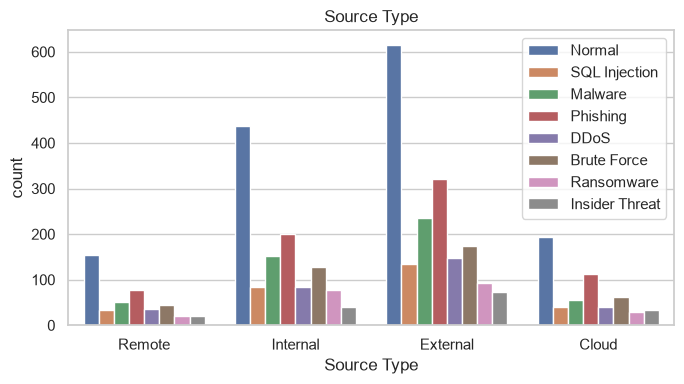

In [74]:
plt.figure(figsize=(7,4))
sns.countplot(data=df, x='Source Type', hue='Threat Type')
plt.title('Source Type')
plt.legend(bbox_to_anchor=(1,1))
plt.tight_layout()
plt.show()

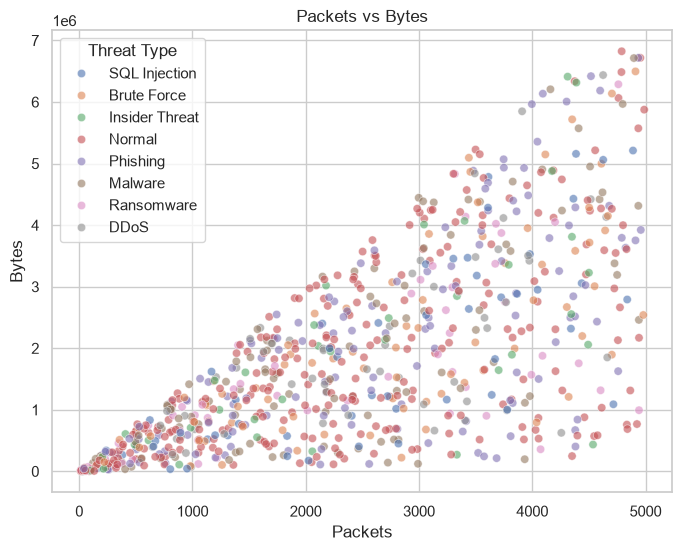

In [75]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df.sample(800, random_state=1), x='Packets', y='Bytes', hue='Threat Type', alpha=0.6)
plt.title('Packets vs Bytes')
plt.show()

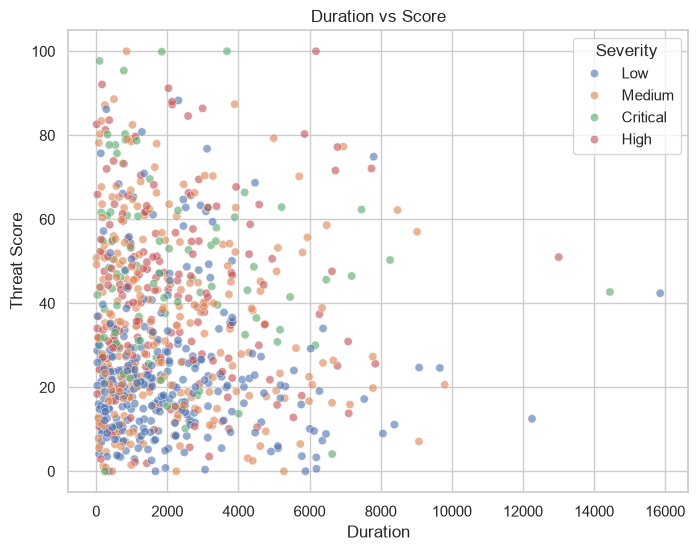

In [76]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df.sample(800, random_state=1), x='Duration', y='Threat Score', hue='Severity', alpha=0.6)
plt.title('Duration vs Score')
plt.show()

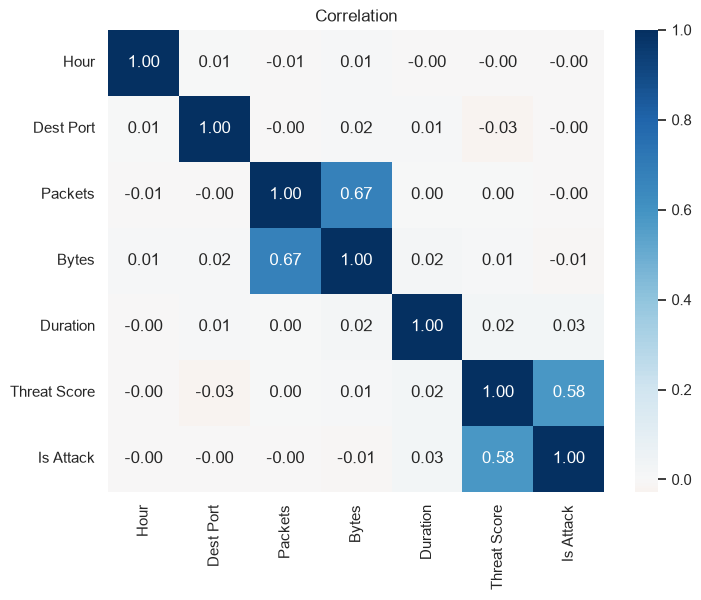

In [77]:
n=df[['Hour','Dest Port','Packets','Bytes','Duration','Threat Score','Is Attack']]
plt.figure(figsize=(8,6))
sns.heatmap(n.corr(), annot=True, cmap='RdBu', center=0, fmt='.2f')
plt.title('Correlation')
plt.show()

Severity        Critical  High  Low  Medium
Threat Type                                
Brute Force           43   130   79     153
DDoS                 119   117   15      54
Insider Threat        13    46   32      78
Malware               56   153   96     190
Normal                15    61  977     348
Phishing              68   210  144     290
Ransomware            96    75   10      38
SQL Injection         26    90   44     134


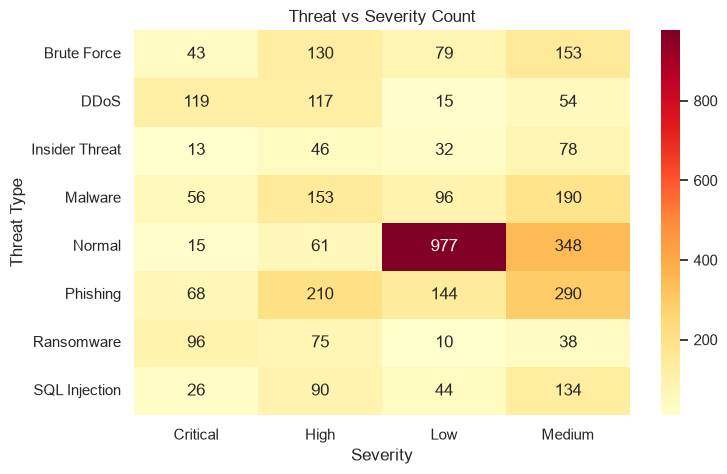

In [78]:
p=df.pivot_table(index='Threat Type', columns='Severity', values='Alert ID', aggfunc='count')
print(p)
plt.figure(figsize=(8,5))
sns.heatmap(p, annot=True, fmt='.0f', cmap='YlOrRd')
plt.title('Threat vs Severity Count')
plt.show()

In [79]:
print(df['Is Attack'].value_counts())

Is Attack
1    2599
0    1401
Name: count, dtype: int64


C:\Users\harsh\AppData\Local\Temp\ipykernel_37988\1131002850.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Is Attack', data=df, palette='Set1')


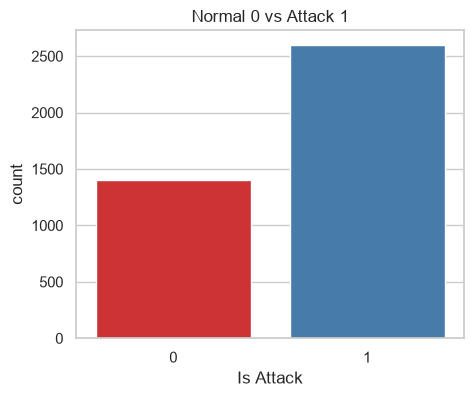

In [80]:
plt.figure(figsize=(5,4))
sns.countplot(x='Is Attack', data=df, palette='Set1')
plt.title('Normal 0 vs Attack 1')
plt.show()

               Packets         Bytes     Duration  Threat Score
Is Attack                                                      
0          2503.576017  1.922378e+06  1958.399001     16.151677
1          2496.092728  1.894634e+06  2083.188149     42.628357


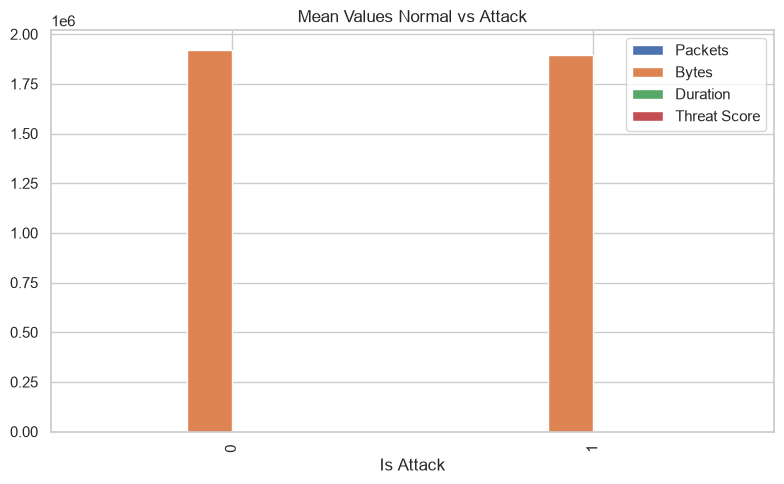

In [81]:
g=df.groupby('Is Attack')[['Packets','Bytes','Duration','Threat Score']].mean()
print(g)
g.plot(kind='bar', figsize=(8,5))
plt.title('Mean Values Normal vs Attack')
plt.tight_layout()
plt.show()

In [82]:
print(df.groupby('Threat Type')['Threat Score'].mean().sort_values(ascending=False))

Threat Type
Ransomware        68.725114
Brute Force       41.312840
Malware           40.680808
DDoS              40.379344
Phishing          40.325983
Insider Threat    38.985799
SQL Injection     38.282993
Normal            16.151677
Name: Threat Score, dtype: float64


In [83]:
print(df.groupby('Status')['Threat Score'].mean())

Status
Blocked          41.028953
Detected         39.357088
Investigating    37.641432
Missed           20.585414
Name: Threat Score, dtype: float64


In [84]:
print('Done')

Done
